In [7]:
# === Cell 1: imports & config ===
import os
from typing import List, Tuple, Dict, Any, Optional

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, random_split
from torch_geometric.data import Batch
import matplotlib.pyplot as plt

# 你的项目里的模块
from model.getdata import smiles2graph
from finetune_pair import load_pretrained_encoders, WeightedFusion

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


class Config:
    # -------- 数据与模型路径（按需修改） --------
    mixture_csv = "mix_noaq.csv"  # 混合溶剂 CSV（不含水的那份）
    encoder_ckpts = [
        "ckpt/tau_0.1__scale_0.25/task_0/best_model.pth",
        "ckpt/tau_0.1__scale_0.25/task_1/best_model.pth",
        "ckpt/tau_0.1__scale_0.25/task_2/best_model.pth",
        "ckpt/tau_0.1__scale_0.25/task_none/best_model.pth",
    ]
    pair_model_ckpt = "ckpt/leeds.pth"  # 单溶剂训练好的 SolvationPredictor

    # 使用哪些 encoder（None = 全部）
    space_indices: Optional[List[int]] = None  # 例： [0, 1, 2, 3]

    # -------- 结构超参数（需和训练时一致） --------
    emb_dim = 512
    solute_dropout = 0.3
    solvent_dropout = 0.3
    mlp_hidden = (1024, 128, 64)
    mlp_dropout = 0.2
    t_embed_dim = 16

    batch_size = 64

    # -------- 输出目录 --------
    out_dir = "results/mixture_tests_noaq"
    exp_name = "jupyter_test"

    # -------- Transformer 头的训练超参数 --------
    attn_d_model = 256
    attn_heads = 4
    attn_layers = 2
    attn_ff_dim = 512
    attn_dropout = 0.1
    attn_hidden = 128

    train_frac = 0.7
    val_frac = 0.15
    num_epochs = 40
    lr = 1e-3
    weight_decay = 0.0
    split_seed = 0


cfg = Config()
EMB_DIM = cfg.emb_dim
os.makedirs(cfg.out_dir, exist_ok=True)


Using device: cuda


In [8]:
# === Cell 2: utils, CSV reading, Dataset ===

def ensure_dir(path: str):
    if path and not os.path.exists(path):
        os.makedirs(path, exist_ok=True)


def _resolve_col(df: pd.DataFrame, logical_name: str, candidates: List[str]) -> str:
    """
    根据一组候选列名（不区分大小写）找到真实列名。
    """
    lowered = {c.lower(): c for c in df.columns}
    for cand in candidates:
        key = cand.lower()
        if key in lowered:
            return lowered[key]
    raise KeyError(
        f"Could not find column for '{logical_name}' among {candidates}, "
        f"available columns: {list(df.columns)}"
    )


def pct_within_1_np(preds: np.ndarray, labels: np.ndarray, thr: float = 1.0) -> float:
    """
    Percentage of samples such that |pred - label| <= thr.
    """
    return float(np.mean(np.abs(preds - labels) <= thr))


def _parse_mixture_component(comp: str) -> Tuple[str, float]:
    """
    解析 "SMI:frac" 或 "frac:SMI" 格式（旧格式时会用到）。
    """
    comp = comp.strip()
    if ":" not in comp:
        raise ValueError(f"Mixture component must contain ':', got '{comp}'")
    a, b = comp.split(":", 1)
    a = a.strip()
    b = b.strip()
    # b 是数字
    try:
        frac = float(b)
        smiles = a
        return smiles, frac
    except ValueError:
        pass
    # a 是数字
    try:
        frac = float(a)
        smiles = b
        return smiles, frac
    except ValueError:
        raise ValueError(
            f"Cannot parse mixture component '{comp}' as SMILES:frac or frac:SMILES"
        )
        

def _smiles_graph_inputs_from_mixture_csv(csv_path: str):
    """
    读入 *混合溶剂* CSV，并统一转换为图 + 数值 + SMILES 列表。

    支持两种格式：
      A. 拆列格式（你现在的 no-aq 表）： 
         solute, solvent1, solvent2, Xsolvent1, T(K), Xsolvent2, s
      B. 旧格式：
         solute_smiles, solvent_smiles = "SMI1:x1;SMI2:x2", temperature, logS
    """
    df = pd.read_csv(csv_path)
    lowered = {c.lower(): c for c in df.columns}

    # ---------- A. 拆列格式 ----------
    has_split = any(name in lowered for name in ["solvent1", "solvent1_smiles"])
    if has_split:
        solute_col = _resolve_col(df, "solute", ["solute_smiles", "solute"])
        solv1_col = _resolve_col(df, "solvent1", ["solvent1_smiles", "solvent1"])
        solv2_col = _resolve_col(df, "solvent2", ["solvent2_smiles", "solvent2"])
        temp_col = _resolve_col(df, "temperature", ["temperature", "t", "T(K)"])
        # 这里假设 s 已经是 logS，如果是线性溶解度需要你提前 log10
        label_col = _resolve_col(df, "logS", ["logS", "logs", "s"])
        frac1_col = _resolve_col(
            df, "Xsolvent1", ["Xsolvent1", "xsolvent1", "frac1", "x1"]
        )
        frac2_col = _resolve_col(
            df, "Xsolvent2", ["Xsolvent2", "xsolvent2", "frac2", "x2"]
        )

        y = df[label_col].astype(float).to_numpy()
        T = df[temp_col].astype(float).to_numpy()
        solute_smiles = df[solute_col].astype(str).tolist()
        solv1_smiles = df[solv1_col].astype(str).tolist()
        solv2_smiles = df[solv2_col].astype(str).tolist()
        frac1 = df[frac1_col].astype(float).to_numpy()
        frac2 = df[frac2_col].astype(float).to_numpy()

    else:
        # ---------- B. 旧格式 ----------
        solute_col = _resolve_col(df, "solute_smiles", ["solute_smiles", "solute"])
        solvent_col = _resolve_col(df, "solvent_smiles", ["solvent_smiles", "solvent"])
        temp_col = _resolve_col(df, "temperature", ["temperature", "t"])
        label_col = _resolve_col(df, "logS", ["logs", "logS"])

        y = df[label_col].astype(float).to_numpy()
        T = df[temp_col].astype(float).to_numpy()

        solute_smiles = df[solute_col].astype(str).tolist()
        solvent_mix = df[solvent_col].astype(str).tolist()

        solv1_smiles: List[str] = []
        solv2_smiles: List[str] = []
        frac1_list: List[float] = []
        frac2_list: List[float] = []

        for s in solvent_mix:
            s = str(s).strip()
            if ";" not in s:
                raise ValueError(
                    f"Mixture solvent string must contain ';' separating components, got '{s}'"
                )
            parts = [p.strip() for p in s.split(";") if p.strip()]
            if len(parts) != 2:
                raise ValueError(
                    f"Expected exactly 2 solvent components like 'SMI1:x1;SMI2:x2', got '{s}'"
                )

            smi1, f1 = _parse_mixture_component(parts[0])
            smi2, f2 = _parse_mixture_component(parts[1])
            solv1_smiles.append(smi1)
            solv2_smiles.append(smi2)
            frac1_list.append(float(f1))
            frac2_list.append(float(f2))

        frac1 = np.array(frac1_list, dtype=float)
        frac2 = np.array(frac2_list, dtype=float)

    # 统一用 smiles2graph 建图
    d1 = smiles2graph(solute_smiles, y=y, properties=T)
    d2_1 = smiles2graph(solv1_smiles, y=y, properties=T)
    d2_2 = smiles2graph(solv2_smiles, y=y, properties=T)

    return d1, d2_1, d2_2, y, T, frac1, frac2, solute_smiles, solv1_smiles, solv2_smiles


class MixtureDataset(Dataset):
    """
    Dataset for *two-solvent mixtures*.
    每个样本返回 10 个字段：
      (solute_graph, solvent1_graph, solvent2_graph,
       temperature, label, frac1, frac2,
       solute_smiles, solv1_smiles, solv2_smiles)
    """
    def __init__(
        self,
        s,
        v1,
        v2,
        temps,
        labels,
        frac1,
        frac2,
        solute_smiles,
        solv1_smiles,
        solv2_smiles,
    ):
        n = len(labels)
        assert len(s) == len(v1) == len(v2) == len(temps) == len(frac1) == len(frac2) == n
        assert len(solute_smiles) == len(solv1_smiles) == len(solv2_smiles) == n

        self.s = s
        self.v1 = v1
        self.v2 = v2
        self.temps = temps
        self.labels = labels
        self.frac1 = frac1
        self.frac2 = frac2
        self.solute_smiles = solute_smiles
        self.solv1_smiles = solv1_smiles
        self.solv2_smiles = solv2_smiles

    def __len__(self) -> int:
        return len(self.labels)

    def __getitem__(self, idx):
        return (
            self.s[idx],
            self.v1[idx],
            self.v2[idx],
            float(self.temps[idx]),
            float(self.labels[idx]),
            float(self.frac1[idx]),
            float(self.frac2[idx]),
            self.solute_smiles[idx],
            self.solv1_smiles[idx],
            self.solv2_smiles[idx],
        )


def collate_mixture(batch):
    """
    Collate function for mixture data.
    """
    (
        sol,
        solv1,
        solv2,
        temps,
        labels,
        frac1,
        frac2,
        solute_smiles,
        solv1_smiles,
        solv2_smiles,
    ) = zip(*batch)

    b1 = Batch.from_data_list(list(sol))
    b2 = Batch.from_data_list(list(solv1))
    b3 = Batch.from_data_list(list(solv2))

    temps = torch.tensor(temps, dtype=torch.float32).view(-1, 1)
    labels = torch.tensor(labels, dtype=torch.float32).view(-1, 1)
    w1 = torch.tensor(frac1, dtype=torch.float32).view(-1, 1)
    w2 = torch.tensor(frac2, dtype=torch.float32).view(-1, 1)

    return (
        b1,
        b2,
        b3,
        temps,
        labels,
        w1,
        w2,
        list(solute_smiles),
        list(solv1_smiles),
        list(solv2_smiles),
    )

def collate_fn_mixture(batch):
    return collate_mixture(batch)


def load_mixture_dataset(csv_path: str) -> MixtureDataset:
    d1, d2_1, d2_2, y, T, frac1, frac2, solute_smiles, solv1_smiles, solv2_smiles = \
        _smiles_graph_inputs_from_mixture_csv(csv_path)
    dataset = MixtureDataset(
        d1, d2_1, d2_2, T, y, frac1, frac2, solute_smiles, solv1_smiles, solv2_smiles
    )
    return dataset


In [9]:
# === Cell 3: base model (linear mixture) ===

def _stack_encode(encs: List[nn.Module], batch: Batch) -> torch.Tensor:
    """
    对一个 Batch 用所有 encoder 编码，并在新维度上 stack：
      输出形状 [B, num_encoders, emb_dim]
    """
    return torch.stack([enc(batch) for enc in encs], dim=1)


class TempPairMLP(nn.Module):
    """
    MLP that combines fused embeddings and embedded temperature.
    """
    def __init__(
        self,
        z_dim: int,
        t_embed_dim: int = 32,
        hidden: Tuple[int, ...] = (1024, 128, 64),
        dropout: float = 0.2,
    ):
        super().__init__()
        self.t_enc = nn.Sequential(nn.Linear(1, t_embed_dim), nn.ReLU())
        in_dim = z_dim * 2 + t_embed_dim

        layers: List[nn.Module] = []
        dims = [in_dim, *hidden, 1]
        for i in range(len(dims) - 2):
            layers += [
                nn.Linear(dims[i], dims[i + 1]),
                nn.ReLU(),
                nn.Dropout(dropout),
            ]
        layers.append(nn.Linear(dims[-2], dims[-1]))
        self.nn = nn.Sequential(*layers)

    def forward(self, z1: torch.Tensor, z2: torch.Tensor, T: torch.Tensor) -> torch.Tensor:
        if T.dim() == 1:
            T = T.unsqueeze(1)
        t = self.t_enc(T.to(z1.device))
        x = torch.cat([z1, z2, t], dim=-1)
        return self.nn(x).squeeze(-1)


class SolvationPredictor(nn.Module):
    """
    单溶剂训练好的模型结构，支持：
      - forward_single(...)：单溶剂
      - forward_mixture_linear(...)：双溶剂线性混合
    """
    def __init__(
        self,
        sol_encs: List[nn.Module],
        solv_encs: List[nn.Module],
        sol_fusion: nn.Module,
        solv_fusion: nn.Module,
        combiner: TempPairMLP,
    ):
        super().__init__()
        self.sol_encs = nn.ModuleList(sol_encs)
        self.solv_encs = nn.ModuleList(solv_encs)
        self.sol_f = sol_fusion
        self.solv_f = solv_fusion
        self.combine = combiner

    # --- 内部：编码 + 融合 ---

    def _fuse(self, fusion: nn.Module, embs: torch.Tensor, g: Optional[torch.Tensor]):
        out = fusion(embs, global_features=g)
        return out[0] if isinstance(out, tuple) else out

    def encode_solute(self, sol_batch: Batch) -> torch.Tensor:
        z = _stack_encode(self.sol_encs, sol_batch)
        g = getattr(sol_batch, "global_features", None)
        z = self._fuse(self.sol_f, z, g)
        return z

    def encode_solvent_fused(self, solv_batch: Batch) -> torch.Tensor:
        """
        用 WeightedFusion 融合后的单溶剂表示（训练时用的那条路径）
        """
        z = _stack_encode(self.solv_encs, solv_batch)
        g = getattr(solv_batch, "global_features", None)
        z = self._fuse(self.solv_f, z, g)
        return z

    def encode_solvent_parts(self, solv_batch: Batch) -> torch.Tensor:
        """
        返回每个 encoder 的溶剂表示 [B, num_parts, emb_dim]，
        不做 WeightedFusion；给 Transformer 用。
        """
        z = _stack_encode(self.solv_encs, solv_batch)
        return z  # [B, K, D]

    # --- 前向接口 ---

    def forward_single(
        self,
        sol_batch: Batch,
        solv_batch: Batch,
        temps: torch.Tensor,
    ) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        """
        单溶剂预测（和训练完全一致）
        """
        z1 = self.encode_solute(sol_batch)
        z2 = self.encode_solvent_fused(solv_batch)
        pred = self.combine(z1, z2, temps)
        return pred, z1, z2

    def forward_mixture_linear(
        self,
        sol_batch: Batch,
        solv_batch_1: Batch,
        solv_batch_2: Batch,
        temps: torch.Tensor,
        frac1: torch.Tensor,
        frac2: torch.Tensor,
    ) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        """
        双溶剂线性混合：先分别得到两个溶剂的 fused 表示，再按摩尔分数线性组合。
        """
        z1 = self.encode_solute(sol_batch)

        z2_1 = self.encode_solvent_fused(solv_batch_1)
        z2_2 = self.encode_solvent_fused(solv_batch_2)

        if frac1.dim() == 1:
            frac1 = frac1.unsqueeze(-1)
        if frac2.dim() == 1:
            frac2 = frac2.unsqueeze(-1)

        frac1 = frac1.to(z2_1.device)
        frac2 = frac2.to(z2_1.device)
        w_sum = frac1 + frac2
        w_sum = torch.where(w_sum == 0, torch.ones_like(w_sum), w_sum)

        w1 = frac1 / w_sum
        w2 = frac2 / w_sum

        z2_mix = w1 * z2_1 + w2 * z2_2
        pred = self.combine(z1, z2_mix, temps)
        return pred, z1, z2_mix


def build_model_subset(
    sample_s,
    sample_v,
    ckpt_paths: List[str],
    solute_dropout: float,
    solvent_dropout: float,
    mlp_hidden: Tuple[int, ...],
    mlp_dropout: float,
    t_embed_dim: int,
) -> SolvationPredictor:
    """
    根据一个样本推断维度，构造 SolvationPredictor 结构。
    """
    solute_encs = load_pretrained_encoders(sample_s, ckpt_paths)
    solvent_encs = load_pretrained_encoders(sample_v, ckpt_paths)

    solute_f = WeightedFusion(len(ckpt_paths), EMB_DIM, dropout=solute_dropout, pair=True).to(device)
    solvent_f = WeightedFusion(len(ckpt_paths), EMB_DIM, dropout=solvent_dropout, pair=True).to(device)

    with torch.no_grad():
        b1 = Batch.from_data_list([sample_s]).to(device)
        b2 = Batch.from_data_list([sample_v]).to(device)
        z1 = _stack_encode(solute_encs, b1)
        z2 = _stack_encode(solvent_encs, b2)
        g1 = getattr(b1, "global_features", None)
        g2 = getattr(b2, "global_features", None)
        z1 = solute_f(z1, global_features=g1)
        z2 = solvent_f(z2, global_features=g2)
        if isinstance(z1, tuple):
            z1 = z1[0]
        if isinstance(z2, tuple):
            z2 = z2[0]
        z_dim = z1.shape[-1]

    comb = TempPairMLP(
        z_dim,
        t_embed_dim=t_embed_dim,
        hidden=mlp_hidden,
        dropout=mlp_dropout,
    ).to(device)

    return SolvationPredictor(solute_encs, solvent_encs, solute_f, solvent_f, comb).to(device)


In [35]:
import torch
import torch.nn as nn
from torch_geometric.data import Batch
from typing import Tuple

# ====== 1. 利用 Transformer + 摩尔分数的溶剂相互作用模块 ======

class SolventInteractionTransformerFrac(nn.Module):
    """
    利用 Transformer 捕捉两种溶剂之间的相互作用，并考虑摩尔分数的影响。
    - 输入: z_a_parts, z_b_parts: [B, P, D]   (4 个空间的表示)
           frac1, frac2: [B, 1]
    - 输出: z_a_fused, z_b_fused: [B, d_model]
           alpha_a, alpha_b: [B, P]  每个溶剂内部 4 个空间的权重
    """
    def __init__(
        self,
        emb_dim: int,
        num_parts: int = 4,
        d_model: int = 256,
        n_heads: int = 4,
        num_layers: int = 2,
        ff_dim: int = 512,
        dropout: float = 0.1,
        attn_hidden: int = 128,
    ):
        super().__init__()
        self.emb_dim = emb_dim
        self.num_parts = num_parts
        self.d_model = d_model

        # 把每个空间的 encoder 输出 [D] 投到 Transformer 的 d_model 维
        self.in_proj = nn.Linear(emb_dim, d_model)

        # solvent id: 0 = A, 1 = B
        self.solvent_embed = nn.Embedding(2, d_model)
        # part id: 0..P-1
        self.part_embed = nn.Embedding(num_parts, d_model)
        # fraction embedding: 标量 frac -> d_model
        self.frac_proj = nn.Linear(1, d_model)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_heads,
            dim_feedforward=ff_dim,
            dropout=dropout,
            batch_first=True,
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

        # cross-conditioned attention pooling for solvent A
        self.attn_a_fc = nn.Linear(d_model * 2, attn_hidden)
        self.attn_a_v = nn.Linear(attn_hidden, 1)

        # cross-conditioned attention pooling for solvent B
        self.attn_b_fc = nn.Linear(d_model * 2, attn_hidden)
        self.attn_b_v = nn.Linear(attn_hidden, 1)

        self.dropout = nn.Dropout(dropout)

    def forward(
        self,
        z_a_parts: torch.Tensor,  # [B, P, D]
        z_b_parts: torch.Tensor,  # [B, P, D]
        frac1: torch.Tensor,      # [B, 1]
        frac2: torch.Tensor,      # [B, 1]
    ) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor]:
        assert z_a_parts.shape == z_b_parts.shape
        B, P, D = z_a_parts.shape
        assert P == self.num_parts and D == self.emb_dim
        device = z_a_parts.device

        # 1) 合并成一个序列 [A1..AP, B1..BP]
        tokens = torch.cat([z_a_parts, z_b_parts], dim=1)  # [B, 2P, D]
        h = self.in_proj(tokens)                            # [B, 2P, d_model]

        # 2) solvent / part embedding
        solvent_ids_a = torch.zeros(B, P, dtype=torch.long, device=device)
        solvent_ids_b = torch.ones(B, P, dtype=torch.long, device=device)
        solvent_ids = torch.cat([solvent_ids_a, solvent_ids_b], dim=1)  # [B, 2P]

        part_ids = torch.arange(P, device=device).unsqueeze(0).expand(B, P)
        part_ids = torch.cat([part_ids, part_ids], dim=1)               # [B, 2P]

        h = h + self.solvent_embed(solvent_ids) + self.part_embed(part_ids)

        # 3) fraction embedding：把 frac1/frac2 映射到 d_model，然后加到对应溶剂的 token 上
        frac1 = frac1.view(B, 1, 1).to(device)
        frac2 = frac2.view(B, 1, 1).to(device)
        frac_emb1 = self.frac_proj(frac1).expand(-1, P, -1)  # [B, P, d_model]
        frac_emb2 = self.frac_proj(frac2).expand(-1, P, -1)
        frac_emb = torch.cat([frac_emb1, frac_emb2], dim=1)  # [B, 2P, d_model]
        h = h + frac_emb

        # 4) Transformer 编码
        h = self.encoder(h)
        h = self.dropout(h)

        h_a = h[:, :P, :]   # [B, P, d_model]
        h_b = h[:, P:, :]   # [B, P, d_model]

        # 5) cross-conditioned attention pooling: A 看到 B 的上下文
        ctx_b = h_b.mean(dim=1, keepdim=True)   # [B, 1, d_model]
        ctx_b_exp = ctx_b.expand(-1, P, -1)

        u_a = torch.tanh(self.attn_a_fc(torch.cat([h_a, ctx_b_exp], dim=-1)))  # [B, P, H]
        e_a = self.attn_a_v(u_a).squeeze(-1)                                   # [B, P]
        alpha_a = torch.softmax(e_a, dim=-1)                                   # [B, P]
        z_a_fused = torch.sum(alpha_a.unsqueeze(-1) * h_a, dim=1)              # [B, d_model]

        # 6) 对称地，B 看到 A 的上下文
        ctx_a = h_a.mean(dim=1, keepdim=True)
        ctx_a_exp = ctx_a.expand(-1, P, -1)

        u_b = torch.tanh(self.attn_b_fc(torch.cat([h_b, ctx_a_exp], dim=-1)))  # [B, P, H]
        e_b = self.attn_b_v(u_b).squeeze(-1)                                   # [B, P]
        alpha_b = torch.softmax(e_b, dim=-1)                                   # [B, P]
        z_b_fused = torch.sum(alpha_b.unsqueeze(-1) * h_b, dim=1)              # [B, d_model]

        return z_a_fused, z_b_fused, alpha_a, alpha_b
        
def init_attn_heads_from_baseline(attn_model: SolvationPredictorAttn,
                                  sample_s,
                                  cfg) -> SolvationPredictorAttn:
    """
    根据当前 encoder 的真实输出维度来初始化：
      - SolventInteractionTransformerFrac（d_model = z_dim_new）
      - TempPairMLP（z_dim = z_dim_new）

    并冻结 encoder，只训练 solvent_interact + combine。
    """
    attn_model.eval()
    # ---- 1. 用一个 sample 图探测 z_dim_new ----
    with torch.no_grad():
        b1 = Batch.from_data_list([sample_s]).to(device)
        z1 = attn_model.encode_solute(b1)    # [1, z_dim_new]
        z_dim_new = z1.shape[-1]

    print(f"[attn-init] detected z_dim_new (solute representation dim) = {z_dim_new}")

    # ---- 2. 初始化 Transformer 交互头：d_model = z_dim_new ----
    attn_model.solvent_interact = SolventInteractionTransformerFrac(
        emb_dim=EMB_DIM,                      # 每个空间 encoder 输出维度（例如 512）
        num_parts=len(attn_model.solv_encs),  # 4 个空间
        d_model=z_dim_new,                    # Transformer 输出和 z1 对齐
        n_heads=cfg.attn_heads,
        num_layers=cfg.attn_layers,
        ff_dim=cfg.attn_ff_dim,
        dropout=cfg.attn_dropout,
        attn_hidden=cfg.attn_hidden,
    ).to(device)

    # ---- 3. 重新新建一个 TempPairMLP：输入维度 = 2*z_dim_new + t_embed_dim ----
    if isinstance(cfg.mlp_hidden, str):
        mlp_hidden = tuple(int(x) for x in cfg.mlp_hidden.split(",") if x.strip())
    elif isinstance(cfg.mlp_hidden, (list, tuple)):
        mlp_hidden = tuple(cfg.mlp_hidden)
    else:
        raise TypeError(f"cfg.mlp_hidden must be str / list / tuple, got {type(cfg.mlp_hidden)}")

    attn_model.combine = TempPairMLP(
        z_dim=z_dim_new,
        t_embed_dim=cfg.t_embed_dim,
        hidden=mlp_hidden,
        dropout=cfg.mlp_dropout,
    ).to(device)

    # ---- 4. 冻结 encoder，只训练新的 Transformer + MLP head ----
    for p in attn_model.parameters():
        p.requires_grad = False

    for p in attn_model.solvent_interact.parameters():
        p.requires_grad = True
    for p in attn_model.combine.parameters():
        p.requires_grad = True

    trainable = sum(p.numel() for p in attn_model.parameters() if p.requires_grad)
    print(f"[attn-init] trainable params = {trainable}")
    return attn_model



class SolvationPredictorAttn(SolvationPredictor):
    """
    在 SolvationPredictor 基础上增加一个 Transformer 头，
    用于建模两种溶剂在 4 个空间上的相互作用（+ 摩尔分数）。
    这里只 **继承** 编码器和 WeightedFusion，不动它们，只加交互 + 新 head。
    """
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        # 这里不在 __init__ 里直接构造 solvent_interact 和 combine，
        # 而是在下面的 init_attn_heads_from_baseline 里根据实际 z_dim_new 来构造
        self.solvent_interact = None  # type: Optional[SolventInteractionTransformerFrac]

    # --- 溶质编码：沿用父类的实现 ---
    def encode_solute(self, sol_batch):
        """
        编码溶质图，整合所有 solute encoder 输出。
        """
        if hasattr(self, "sol_encs"):
            zs = []
            for enc in self.sol_encs:
                z_i = enc(sol_batch)
                zs.append(z_i)
            z = torch.stack(zs, dim=1).mean(dim=1)  # [B, D]
        elif hasattr(self, "solute_encoder"):
            z = self.solute_encoder(sol_batch)
        else:
            raise AttributeError("SolvationPredictorAttn: missing solute encoder (sol_encs or solute_encoder)")
        return z


    # --- 溶剂 4 空间的 encoder 输出（不做融合） ---
    def encode_solvent_parts(self, solv_batch: Batch) -> torch.Tensor:
        """
        返回每个溶剂在 K 个预训练空间下的原始 encoder 输出:
            [B, K, EMB_DIM]
        这里不做 WeightedFusion，把每个 encoder 的输出直接堆叠给 Transformer 用。
        """
        zs = []
        for enc in self.solv_encs:
            z = enc(solv_batch)        # [B, EMB_DIM]
            zs.append(z)
        z = torch.stack(zs, dim=1)     # [B, K, EMB_DIM]
        return z

    def forward_mixture_attn(
        self,
        sol_batch: Batch,
        solv_batch_1: Batch,
        solv_batch_2: Batch,
        temps: torch.Tensor,
        frac1: torch.Tensor,
        frac2: torch.Tensor,
    ):
        """
        返回:
          pred      : [B]
          alpha_a   : [B, K] 溶剂1在 K 个空间上的注意力权重
          alpha_b   : [B, K] 溶剂2在 K 个空间上的注意力权重
          z2_mix    : [B, d_model] 最终混合溶剂表示
        """
        # 1) 溶质表示（使用 baseline 的 GNN + WeightedFusion）
        z1 = self.encode_solute(sol_batch)   # [B, z_dim_new]

        # 2) 两个溶剂，各自 K 个空间的 encoder 输出: [B, K, EMB_DIM]
        z2_parts_1 = self.encode_solvent_parts(solv_batch_1)
        z2_parts_2 = self.encode_solvent_parts(solv_batch_2)

        if frac1.dim() == 1:
            frac1 = frac1.unsqueeze(-1)
        if frac2.dim() == 1:
            frac2 = frac2.unsqueeze(-1)

        frac1 = frac1.to(z1.device)
        frac2 = frac2.to(z1.device)

        # 3) Transformer + 摩尔分数交互
        z2a_ctx, z2b_ctx, alpha_a, alpha_b = self.solvent_interact(
            z2_parts_1, z2_parts_2, frac1, frac2
        )   # [B, d_model], [B, d_model], [B, K], [B, K]

        # 4) 最后按比例线性组合两个溶剂整体表示
        w_sum = frac1 + frac2
        w_sum = torch.where(w_sum == 0, torch.ones_like(w_sum), w_sum)
        w1 = frac1 / w_sum
        w2 = frac2 / w_sum

        z2_mix = w1 * z2a_ctx + w2 * z2b_ctx   # [B, d_model]

        # 5) 喂给新的 TempPairMLP（维度已经在 init_attn_heads_from_baseline 里对齐）
        pred = self.combine(z1, z2_mix, temps)  # [B]
        return pred, alpha_a, alpha_b
        


In [11]:
def build_attn_model_from_baseline(
    baseline_model: SolvationPredictor,
    emb_dim: int,
    cfg,
) -> SolvationPredictorAttn:
    """
    基于已经 load 好权重的 baseline_model 构建带 Transformer 交互的模型，
    并且只训练新加的 solvent_interact 参数。
    cfg 里需要有：
        attn_d_model, attn_heads, attn_layers, attn_ff_dim, attn_dropout, attn_hidden
    """
    # 1) 创建带 attention 的新模型实例
    attn_model = SolvationPredictorAttn(
        base_model=baseline_model,
        emb_dim=emb_dim,
        d_model=cfg.attn_d_model,
        n_heads=cfg.attn_heads,
        num_layers=cfg.attn_layers,
        ff_dim=cfg.attn_ff_dim,
        dropout=cfg.attn_dropout,
        attn_hidden=cfg.attn_hidden,
    ).to(device)

    # 2) 冻结所有旧参数，只训练 solvent_interact.*
    for name, p in attn_model.named_parameters():
        if name.startswith("solvent_interact."):
            p.requires_grad_(True)
        else:
            p.requires_grad_(False)

    # 打印一下确认
    trainable = [(n, p.numel()) for n, p in attn_model.named_parameters() if p.requires_grad]
    print("[attn-model] Trainable parameters:")
    for n, npar in trainable:
        print(f"  - {n}: {npar} params")
    print(f"[attn-model] Total trainable params: {sum(npar for _, npar in trainable)}")

    return attn_model


In [12]:
# === Cell 5: checkpoint loading & evaluation ===

def load_old_ckpt_with_rename(model: nn.Module, ckpt_path: str, device):
    """
    把老版本 state_dict 的名字映射到当前 SolvationPredictor 的名字。
    """
    ck = torch.load(ckpt_path, map_location=device)
    state = ck.get("model_state_dict", ck)

    new_state = {}
    for k, v in state.items():
        new_k = k

        if new_k.startswith("solute_encs."):
            new_k = new_k.replace("solute_encs.", "sol_encs.")
        elif new_k.startswith("solvent_encs."):
            new_k = new_k.replace("solvent_encs.", "solv_encs.")
        elif new_k.startswith("solute_fusion."):
            new_k = new_k.replace("solute_fusion.", "sol_f.")
        elif new_k.startswith("solvent_fusion."):
            new_k = new_k.replace("solvent_fusion.", "solv_f.")
        elif new_k.startswith("combiner."):
            new_k = new_k.replace("combiner.", "combine.")
            new_k = new_k.replace("mlp.", "nn.")

        new_state[new_k] = v

    missing, unexpected = model.load_state_dict(new_state, strict=False)
    print("[rename-load] Missing keys after remap:", missing)
    print("[rename-load] Unexpected keys after remap:", unexpected)
    return model


def build_model_from_cfg(attn: bool = False) -> nn.Module:
    """
    用 cfg 配置 + mixture_csv 里的第一个样本，构造模型结构并加载 checkpoint。
    """
    dataset = load_mixture_dataset(cfg.mixture_csv)
    sample_s = dataset.s[0]
    sample_v = dataset.v1[0]

    if cfg.space_indices is None:
        subset_indices = list(range(len(cfg.encoder_ckpts)))
    else:
        subset_indices = cfg.space_indices
    ckpt_paths_subset = [cfg.encoder_ckpts[i] for i in subset_indices]
    print("[info] Using encoder indices:", subset_indices)
    for idx, path in zip(subset_indices, ckpt_paths_subset):
        print(f"   - index {idx}: {path}")

    model_cls = SolvationPredictorAttn if attn else SolvationPredictor
    model = build_model_subset(
        sample_s=sample_s,
        sample_v=sample_v,
        ckpt_paths=ckpt_paths_subset,
        solute_dropout=cfg.solute_dropout,
        solvent_dropout=cfg.solvent_dropout,
        mlp_hidden=cfg.mlp_hidden,
        mlp_dropout=cfg.mlp_dropout,
        t_embed_dim=cfg.t_embed_dim,
    )
    model.__class__ = model_cls  # 复用已有参数 + 增加 attn 模块

    model = load_old_ckpt_with_rename(model, cfg.pair_model_ckpt, device)
    model.to(device)
    return model


def evaluate_mixture_linear(
    model: SolvationPredictor,
    loader: DataLoader,
    out_csv_path: Optional[str] = None,
) -> Tuple[float, float]:
    """
    用线性混合在 loader 上评估，输出整体 MSE 和 pct(|err|<=1)，
    如 out_csv_path 不为空，则写出逐样本预测 CSV。
    """
    model.eval()
    mse_fn = nn.MSELoss()

    preds = []
    labs = []
    temps_all, frac1_all, frac2_all = [], [], []
    solute_all, solv1_all, solv2_all = [], [], []

    with torch.no_grad():
        for batch in loader:
            (
                s_batch,
                v1_batch,
                v2_batch,
                temps,
                labels,
                frac1,
                frac2,
                solute_smiles,
                solv1_smiles,
                solv2_smiles,
            ) = batch

            s_batch = s_batch.to(device)
            v1_batch = v1_batch.to(device)
            v2_batch = v2_batch.to(device)
            temps = temps.to(device)
            labels = labels.view(-1).to(device)
            frac1 = frac1.to(device)
            frac2 = frac2.to(device)

            p, _, _ = model.forward_mixture_linear(
                s_batch,
                v1_batch,
                v2_batch,
                temps,
                frac1,
                frac2,
            )

            preds.append(p.detach().cpu().numpy())
            labs.append(labels.detach().cpu().numpy())
            temps_all.extend(temps.view(-1).cpu().tolist())
            frac1_all.extend(frac1.view(-1).cpu().tolist())
            frac2_all.extend(frac2.view(-1).cpu().tolist())
            solute_all.extend(solute_smiles)
            solv1_all.extend(solv1_smiles)
            solv2_all.extend(solv2_smiles)

    preds_np = np.concatenate(preds)
    labs_np = np.concatenate(labs)

    if out_csv_path is not None:
        ensure_dir(os.path.dirname(out_csv_path))
        df_pred = pd.DataFrame(
            {
                "solute_smiles": solute_all,
                "solvent1_smiles": solv1_all,
                "solvent2_smiles": solv2_all,
                "temperature": temps_all,
                "frac1": frac1_all,
                "frac2": frac2_all,
                "y_true": labs_np,
                "y_pred": preds_np,
            }
        )
        df_pred.to_csv(out_csv_path, index=False)

    mse_val = float(mse_fn(torch.tensor(preds_np), torch.tensor(labs_np)))
    pct1 = pct_within_1_np(preds_np, labs_np)
    return mse_val, pct1


def evaluate_mixture_attn(
    model: SolvationPredictorAttn,
    loader: DataLoader,
    out_csv_path: Optional[str] = None,
) -> Tuple[float, float]:
    """
    用 Transformer 相互作用头在 loader 上评估。
    除预测外，还会把每个溶剂的 4 个空间注意力权重写入 CSV。
    """
    model.eval()
    mse_fn = nn.MSELoss()

    preds, labs = [], []
    temps_all, frac1_all, frac2_all = [], [], []
    solute_all, solv1_all, solv2_all = [], [], []
    alpha_a_all, alpha_b_all = [], []

    with torch.no_grad():
        for batch in loader:
            (
                s_batch,
                v1_batch,
                v2_batch,
                temps,
                labels,
                frac1,
                frac2,
                solute_smiles,
                solv1_smiles,
                solv2_smiles,
            ) = batch

            s_batch = s_batch.to(device)
            v1_batch = v1_batch.to(device)
            v2_batch = v2_batch.to(device)
            temps = temps.to(device)
            labels = labels.view(-1).to(device)
            frac1 = frac1.to(device)
            frac2 = frac2.to(device)

            p, alpha_a, alpha_b = model.forward_mixture_attn(
                s_batch,
                v1_batch,
                v2_batch,
                temps,
                frac1,
                frac2,
            )

            preds.append(p.detach().cpu().numpy())
            labs.append(labels.detach().cpu().numpy())
            temps_all.extend(temps.view(-1).cpu().tolist())
            frac1_all.extend(frac1.view(-1).cpu().tolist())
            frac2_all.extend(frac2.view(-1).cpu().tolist())
            solute_all.extend(solute_smiles)
            solv1_all.extend(solv1_smiles)
            solv2_all.extend(solv2_smiles)
            alpha_a_all.append(alpha_a.detach().cpu().numpy())
            alpha_b_all.append(alpha_b.detach().cpu().numpy())

    preds_np = np.concatenate(preds)
    labs_np = np.concatenate(labs)
    alpha_a_np = np.concatenate(alpha_a_all)  # [N, K]
    alpha_b_np = np.concatenate(alpha_b_all)  # [N, K]

    if out_csv_path is not None:
        ensure_dir(os.path.dirname(out_csv_path))
        data = {
            "solute_smiles": solute_all,
            "solvent1_smiles": solv1_all,
            "solvent2_smiles": solv2_all,
            "temperature": temps_all,
            "frac1": frac1_all,
            "frac2": frac2_all,
            "y_true": labs_np,
            "y_pred": preds_np,
        }
        K = alpha_a_np.shape[1]
        for k in range(K):
            data[f"alpha_a_{k}"] = alpha_a_np[:, k]
            data[f"alpha_b_{k}"] = alpha_b_np[:, k]

        df_pred = pd.DataFrame(data)
        df_pred.to_csv(out_csv_path, index=False)

    mse_val = float(mse_fn(torch.tensor(preds_np), torch.tensor(labs_np)))
    pct1 = pct_within_1_np(preds_np, labs_np)
    return mse_val, pct1


In [13]:
# === Cell 5: checkpoint loading & evaluation ===

def load_old_ckpt_with_rename(model: nn.Module, ckpt_path: str, device):
    """
    把老版本 state_dict 的名字映射到当前 SolvationPredictor 的名字。
    """
    ck = torch.load(ckpt_path, map_location=device)
    state = ck.get("model_state_dict", ck)

    new_state = {}
    for k, v in state.items():
        new_k = k

        if new_k.startswith("solute_encs."):
            new_k = new_k.replace("solute_encs.", "sol_encs.")
        elif new_k.startswith("solvent_encs."):
            new_k = new_k.replace("solvent_encs.", "solv_encs.")
        elif new_k.startswith("solute_fusion."):
            new_k = new_k.replace("solute_fusion.", "sol_f.")
        elif new_k.startswith("solvent_fusion."):
            new_k = new_k.replace("solvent_fusion.", "solv_f.")
        elif new_k.startswith("combiner."):
            new_k = new_k.replace("combiner.", "combine.")
            new_k = new_k.replace("mlp.", "nn.")

        new_state[new_k] = v

    missing, unexpected = model.load_state_dict(new_state, strict=False)
    print("[rename-load] Missing keys after remap:", missing)
    print("[rename-load] Unexpected keys after remap:", unexpected)
    return model


def build_model_from_cfg(attn: bool = False) -> nn.Module:
    """
    用 cfg 配置 + mixture_csv 里的第一个样本，构造模型结构并加载 checkpoint。
    """
    dataset = load_mixture_dataset(cfg.mixture_csv)
    sample_s = dataset.s[0]
    sample_v = dataset.v1[0]

    if cfg.space_indices is None:
        subset_indices = list(range(len(cfg.encoder_ckpts)))
    else:
        subset_indices = cfg.space_indices
    ckpt_paths_subset = [cfg.encoder_ckpts[i] for i in subset_indices]
    print("[info] Using encoder indices:", subset_indices)
    for idx, path in zip(subset_indices, ckpt_paths_subset):
        print(f"   - index {idx}: {path}")

    model_cls = SolvationPredictorAttn if attn else SolvationPredictor
    model = build_model_subset(
        sample_s=sample_s,
        sample_v=sample_v,
        ckpt_paths=ckpt_paths_subset,
        solute_dropout=cfg.solute_dropout,
        solvent_dropout=cfg.solvent_dropout,
        mlp_hidden=cfg.mlp_hidden,
        mlp_dropout=cfg.mlp_dropout,
        t_embed_dim=cfg.t_embed_dim,
    )
    model.__class__ = model_cls  # 复用已有参数 + 增加 attn 模块

    model = load_old_ckpt_with_rename(model, cfg.pair_model_ckpt, device)
    model.to(device)
    return model


def evaluate_mixture_linear(
    model: SolvationPredictor,
    loader: DataLoader,
    out_csv_path: Optional[str] = None,
) -> Tuple[float, float]:
    """
    用线性混合在 loader 上评估，输出整体 MSE 和 pct(|err|<=1)，
    如 out_csv_path 不为空，则写出逐样本预测 CSV。
    """
    model.eval()
    mse_fn = nn.MSELoss()

    preds = []
    labs = []
    temps_all, frac1_all, frac2_all = [], [], []
    solute_all, solv1_all, solv2_all = [], [], []

    with torch.no_grad():
        for batch in loader:
            (
                s_batch,
                v1_batch,
                v2_batch,
                temps,
                labels,
                frac1,
                frac2,
                solute_smiles,
                solv1_smiles,
                solv2_smiles,
            ) = batch

            s_batch = s_batch.to(device)
            v1_batch = v1_batch.to(device)
            v2_batch = v2_batch.to(device)
            temps = temps.to(device)
            labels = labels.view(-1).to(device)
            frac1 = frac1.to(device)
            frac2 = frac2.to(device)

            p, _, _ = model.forward_mixture_linear(
                s_batch,
                v1_batch,
                v2_batch,
                temps,
                frac1,
                frac2,
            )

            preds.append(p.detach().cpu().numpy())
            labs.append(labels.detach().cpu().numpy())
            temps_all.extend(temps.view(-1).cpu().tolist())
            frac1_all.extend(frac1.view(-1).cpu().tolist())
            frac2_all.extend(frac2.view(-1).cpu().tolist())
            solute_all.extend(solute_smiles)
            solv1_all.extend(solv1_smiles)
            solv2_all.extend(solv2_smiles)

    preds_np = np.concatenate(preds)
    labs_np = np.concatenate(labs)

    if out_csv_path is not None:
        ensure_dir(os.path.dirname(out_csv_path))
        df_pred = pd.DataFrame(
            {
                "solute_smiles": solute_all,
                "solvent1_smiles": solv1_all,
                "solvent2_smiles": solv2_all,
                "temperature": temps_all,
                "frac1": frac1_all,
                "frac2": frac2_all,
                "y_true": labs_np,
                "y_pred": preds_np,
            }
        )
        df_pred.to_csv(out_csv_path, index=False)

    mse_val = float(mse_fn(torch.tensor(preds_np), torch.tensor(labs_np)))
    pct1 = pct_within_1_np(preds_np, labs_np)
    return mse_val, pct1


def evaluate_mixture_attn(
    model: SolvationPredictorAttn,
    loader: DataLoader,
    out_csv_path: Optional[str] = None,
) -> Tuple[float, float]:
    """
    用 Transformer 相互作用头在 loader 上评估。
    除预测外，还会把每个溶剂的 4 个空间注意力权重写入 CSV。
    """
    model.eval()
    mse_fn = nn.MSELoss()

    preds, labs = [], []
    temps_all, frac1_all, frac2_all = [], [], []
    solute_all, solv1_all, solv2_all = [], [], []
    alpha_a_all, alpha_b_all = [], []

    with torch.no_grad():
        for batch in loader:
            (
                s_batch,
                v1_batch,
                v2_batch,
                temps,
                labels,
                frac1,
                frac2,
                solute_smiles,
                solv1_smiles,
                solv2_smiles,
            ) = batch

            s_batch = s_batch.to(device)
            v1_batch = v1_batch.to(device)
            v2_batch = v2_batch.to(device)
            temps = temps.to(device)
            labels = labels.view(-1).to(device)
            frac1 = frac1.to(device)
            frac2 = frac2.to(device)

            p, alpha_a, alpha_b = model.forward_mixture_attn(
                s_batch,
                v1_batch,
                v2_batch,
                temps,
                frac1,
                frac2,
            )

            preds.append(p.detach().cpu().numpy())
            labs.append(labels.detach().cpu().numpy())
            temps_all.extend(temps.view(-1).cpu().tolist())
            frac1_all.extend(frac1.view(-1).cpu().tolist())
            frac2_all.extend(frac2.view(-1).cpu().tolist())
            solute_all.extend(solute_smiles)
            solv1_all.extend(solv1_smiles)
            solv2_all.extend(solv2_smiles)
            alpha_a_all.append(alpha_a.detach().cpu().numpy())
            alpha_b_all.append(alpha_b.detach().cpu().numpy())

    preds_np = np.concatenate(preds)
    labs_np = np.concatenate(labs)
    alpha_a_np = np.concatenate(alpha_a_all)  # [N, K]
    alpha_b_np = np.concatenate(alpha_b_all)  # [N, K]

    if out_csv_path is not None:
        ensure_dir(os.path.dirname(out_csv_path))
        data = {
            "solute_smiles": solute_all,
            "solvent1_smiles": solv1_all,
            "solvent2_smiles": solv2_all,
            "temperature": temps_all,
            "frac1": frac1_all,
            "frac2": frac2_all,
            "y_true": labs_np,
            "y_pred": preds_np,
        }
        K = alpha_a_np.shape[1]
        for k in range(K):
            data[f"alpha_a_{k}"] = alpha_a_np[:, k]
            data[f"alpha_b_{k}"] = alpha_b_np[:, k]

        df_pred = pd.DataFrame(data)
        df_pred.to_csv(out_csv_path, index=False)

    mse_val = float(mse_fn(torch.tensor(preds_np), torch.tensor(labs_np)))
    pct1 = pct_within_1_np(preds_np, labs_np)
    return mse_val, pct1


In [14]:
# === Cell 7: training loop for Transformer head ===

def make_split_loaders_from_dataset(
    dataset: MixtureDataset,
    batch_size: int,
    train_frac: float,
    val_frac: float,
    seed: int = 0,
):
    n_total = len(dataset)
    n_train = int(n_total * train_frac)
    n_val = int(n_total * val_frac)
    n_test = n_total - n_train - n_val
    gen = torch.Generator().manual_seed(seed)
    train_ds, val_ds, test_ds = random_split(dataset, [n_train, n_val, n_test], generator=gen)

    def make_loader(ds, shuffle):
        return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, collate_fn=collate_mixture)

    return (
        make_loader(train_ds, True),
        make_loader(val_ds, False),
        make_loader(test_ds, False),
    )


def train_transformer_head(
    model,
    train_loader,
    val_loader,
    num_epochs: int,
    lr: float,
    weight_decay: float,
    out_dir: str,
):
    """
    只训练（或优先训练）attention 相关 head 的函数。
    修正版：如果发现没有任何 requires_grad=True 的参数，
    会自动尝试解冻 attention 模块；再不行就解冻整个模型。
    """
    model.to(device)

    # 1) 先看看当前有哪些参数是 requires_grad=True
    params = [p for p in model.parameters() if p.requires_grad]

    # 如果是空的，说明之前把整个模型都冻住了
    if len(params) == 0:
        print("[train-attn] WARNING: no params with requires_grad=True; "
              "trying to unfreeze attention-related modules...")

        # 先尝试只解冻名字里面带这些关键词的模块
        ATTN_KEYS = ["attn", "interaction", "transformer", "mix_head", "mix_head", "attn_head"]
        for name, p in model.named_parameters():
            if any(k in name.lower() for k in ATTN_KEYS):
                p.requires_grad_(True)

        params = [p for p in model.parameters() if p.requires_grad]

        # 如果还是空，就解冻整个模型，至少保证能训练
        if len(params) == 0:
            print("[train-attn] Still no trainable params, unfreezing the whole model.")
            for p in model.parameters():
                p.requires_grad_(True)
            params = list(model.parameters())

    # 打印一下目前真正会被训练的参数数量
    n_trainable = sum(p.numel() for p in params)
    print(f"[train-attn] Trainable params: {n_trainable}")

    optimizer = torch.optim.Adam(params, lr=lr, weight_decay=weight_decay)
    mse_fn = nn.MSELoss()

    train_losses, val_losses = [], []

    best_val = float("inf")
    best_state = None

    for epoch in range(1, num_epochs + 1):
        # ---------- train ----------
        model.train()
        total_loss = 0.0
        n_samples = 0

        for batch in train_loader:
            (
                s_batch,
                v1_batch,
                v2_batch,
                temps,
                labels,
                frac1,
                frac2,
                *_,
            ) = batch

            s_batch = s_batch.to(device)
            v1_batch = v1_batch.to(device)
            v2_batch = v2_batch.to(device)
            temps = temps.to(device)
            labels = labels.view(-1).to(device)
            frac1 = frac1.to(device)
            frac2 = frac2.to(device)

            optimizer.zero_grad()

            if hasattr(model, "forward_mixture_attn"):
                pred, _, _, _ = model.forward_mixture_attn(
                    s_batch, v1_batch, v2_batch, temps, frac1, frac2
                )
            else:
                pred, _, _ = model.forward_mixture(
                    s_batch, v1_batch, v2_batch, temps, frac1, frac2
                )

            loss = mse_fn(pred.view(-1), labels)
            loss.backward()
            optimizer.step()

            bs = labels.size(0)
            total_loss += loss.item() * bs
            n_samples += bs

        train_loss = total_loss / max(n_samples, 1)
        train_losses.append(train_loss)

        # ---------- val ----------
        model.eval()
        val_total = 0.0
        val_n = 0
        with torch.no_grad():
            for batch in val_loader:
                (
                    s_batch,
                    v1_batch,
                    v2_batch,
                    temps,
                    labels,
                    frac1,
                    frac2,
                    *_,
                ) = batch

                s_batch = s_batch.to(device)
                v1_batch = v1_batch.to(device)
                v2_batch = v2_batch.to(device)
                temps = temps.to(device)
                labels = labels.view(-1).to(device)
                frac1 = frac1.to(device)
                frac2 = frac2.to(device)

                if hasattr(model, "forward_mixture_attn"):
                    pred, _, _, _ = model.forward_mixture_attn(
                        s_batch, v1_batch, v2_batch, temps, frac1, frac2
                    )
                else:
                    pred, _, _ = model.forward_mixture(
                        s_batch, v1_batch, v2_batch, temps, frac1, frac2
                    )

                loss = mse_fn(pred.view(-1), labels)
                val_total += loss.item() * labels.size(0)
                val_n += labels.size(0)

        val_loss = val_total / max(val_n, 1)
        val_losses.append(val_loss)

        print(f"[train-attn] Epoch {epoch:03d} | "
              f"train MSE={train_loss:.4f} | val MSE={val_loss:.4f}")

        # 记录最优
        if val_loss < best_val:
            best_val = val_loss
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

    # 训练结束后，保存 loss 曲线
    ensure_dir(out_dir)
    loss_csv = os.path.join(out_dir, "attn_training_curve.csv")
    pd.DataFrame({"epoch": np.arange(1, num_epochs+1),
                  "train_mse": train_losses,
                  "val_mse": val_losses}).to_csv(loss_csv, index=False)
    print(f"[train-attn] Training curve saved to: {loss_csv}")

    # 加载 best state
    if best_state is not None:
        model.load_state_dict(best_state)

    return model, train_losses, val_losses


In [15]:
# === re-define per-pair analysis & plotting ===
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 如果前面已经有 ensure_dir，可以删掉这里这一小段
try:
    ensure_dir
except NameError:
    def ensure_dir(path: str):
        if path and not os.path.exists(path):
            os.makedirs(path, exist_ok=True)

def analyze_per_pair_from_pred(
    pred_csv_path: str,
    original_csv_path: Optional[str] = None,
    out_csv_path: Optional[str] = None,
) -> pd.DataFrame:
    """
    基于预测 CSV（包含 solvent1_smiles, solvent2_smiles, y_true, y_pred），
    计算每个溶剂对的平均 MSE / MAE / count，并可写出汇总 CSV。
    """
    df_pred = pd.read_csv(pred_csv_path)
    for col in ("solvent1_smiles", "solvent2_smiles", "y_true", "y_pred"):
        if col not in df_pred.columns:
            raise KeyError(f"Expected column '{col}' in {pred_csv_path}")

    df = df_pred.copy()
    df["sq_err"] = (df["y_pred"] - df["y_true"]) ** 2
    df["abs_err"] = (df["y_pred"] - df["y_true"]).abs()

    # 无序溶剂对 key
    def canonical_pair(row):
        a = str(row["solvent1_smiles"])
        b = str(row["solvent2_smiles"])
        return tuple(sorted([a, b]))

    df["pair_key"] = df.apply(canonical_pair, axis=1)

    grp = df.groupby("pair_key").agg(
        mse=("sq_err", "mean"),
        mae=("abs_err", "mean"),
        count=("sq_err", "size"),
        solvent1_smiles=("solvent1_smiles", lambda x: x.mode().iat[0] if not x.mode().empty else x.iloc[0]),
        solvent2_smiles=("solvent2_smiles", lambda x: x.mode().iat[0] if not x.mode().empty else x.iloc[0]),
    ).reset_index(drop=True)

    # 尝试从原始 CSV 里查人类可读名称（如果有）
    smiles2name = {}
    if original_csv_path is not None and os.path.isfile(original_csv_path):
        df_orig = pd.read_csv(original_csv_path)
        cols = df_orig.columns
        tmp = []
        if "solvent1_smiles" in cols and "solvent1" in cols:
            tmp.append(df_orig[["solvent1_smiles", "solvent1"]].rename(
                columns={"solvent1_smiles": "smi", "solvent1": "name"}))
        if "solvent2_smiles" in cols and "solvent2" in cols:
            tmp.append(df_orig[["solvent2_smiles", "solvent2"]].rename(
                columns={"solvent2_smiles": "smi", "solvent2": "name"}))
        if tmp:
            mapdf = pd.concat(tmp, ignore_index=True).dropna()
            smiles2name = mapdf.groupby("smi")["name"].agg(
                lambda x: x.mode().iat[0] if not x.mode().empty else x.iloc[0]
            ).to_dict()

    def lookup_name(smi):
        return smiles2name.get(smi, smi)

    grp["solventA_smiles"] = grp["solvent1_smiles"]
    grp["solventB_smiles"] = grp["solvent2_smiles"]
    grp["solventA_name"] = grp["solventA_smiles"].map(lookup_name)
    grp["solventB_name"] = grp["solventB_smiles"].map(lookup_name)

    grp_sorted = grp.sort_values("mse", ascending=True).reset_index(drop=True)

    if out_csv_path is not None:
        ensure_dir(os.path.dirname(out_csv_path))
        grp_sorted.to_csv(out_csv_path, index=False)
        print(f"[pair-summary] Saved {len(grp_sorted)} rows to: {out_csv_path}")

    print("Top solvent combinations by average MSE:")
    print(
        grp_sorted[
            ["solventA_name", "solventB_name", "solventA_smiles", "solventB_smiles", "mse", "mae", "count"]
        ].head(20)
    )
    return grp_sorted


# 溶剂类型字典：和之前的一致
solvent_type = {
    # 非极性
    "CCCCCCC":   "NP",
    "CCCCCC":    "NP",
    "C1CCCCC1":  "NP",
    # 卤代
    "C(Cl)(Cl)(Cl)":              "Hal",
    "C(Cl)Cl":                    "Hal",
    "C(=C(Cl)Cl)Cl":              "Hal",
    "C(=C(Cl)Cl)(Cl)Cl":          "Hal",
    "CC(Cl)(Cl)Cl":               "Hal",
    "FC(F)(Cl)C(F)(Cl)Cl":        "Hal",
    "FC(F)(Cl)C(Cl)Cl":           "Hal",
    "FC(Cl)C(F)(Cl)Cl":           "Hal",
    "C(I)I":                      "Hal",
    # 醇类
    "CCO":       "HBD",
    "CC(C)O":    "HBD",
    "CCCCO":     "HBD",
    # 羰基 / 醚 / 环醚
    "CC(=O)C":       "HBA",
    "CCOC(=O)C":     "HBA",
    "CCCCOC(=O)C":   "HBA",
    "C1CCOC1":       "HBA",
    "O1CCOCC1":      "HBA",
    # π 体系
    "Cc1ccccc1": "Pi",
}

def classify_solvent(smiles: str) -> str:
    return solvent_type.get(str(smiles), "Unknown")


def plot_scatter_from_predictions(
    pred_csv_path: str,
    title_prefix: str = "",
    save_prefix: Optional[str] = None,
):
    df = pd.read_csv(pred_csv_path)

    # 溶剂对标签（按 SMILES 排序）
    df["solvent_pair"] = df.apply(
        lambda row: " + ".join(sorted([row["solvent1_smiles"], row["solvent2_smiles"]])),
        axis=1,
    )
    pairs = df["solvent_pair"].unique()
    n_pairs = len(pairs)

    # 每个溶剂对一种颜色
    cmap_pairs = plt.cm.get_cmap("tab20", n_pairs)
    pair_colors = {pair: cmap_pairs(i) for i, pair in enumerate(pairs)}

    # 溶剂类型组合
    df["type1"] = df["solvent1_smiles"].apply(classify_solvent)
    df["type2"] = df["solvent2_smiles"].apply(classify_solvent)
    df["pair_class"] = df.apply(
        lambda row: " + ".join(sorted([row["type1"], row["type2"]])),
        axis=1,
    )
    classes = df["pair_class"].unique()
    n_classes = len(classes)
    cmap_cls = plt.cm.get_cmap("tab10", n_classes)
    class_colors = {cls: cmap_cls(i) for i, cls in enumerate(classes)}

    def setup_equal_axes_with_band(ax, df_local, band=1.0):
        x_min = df_local["y_true"].min()
        x_max = df_local["y_true"].max()
        y_min = df_local["y_pred"].min()
        y_max = df_local["y_pred"].max()
        min_val = min(x_min, y_min)
        max_val = max(x_max, y_max)
        margin = 0.3
        lo = min_val - margin
        hi = max_val + margin
        ax.set_xlim(lo, hi)
        ax.set_ylim(lo, hi)

        x_line = np.linspace(lo, hi, 200)
        ax.plot(x_line, x_line, linestyle="--", linewidth=1, label="y = x")
        ax.fill_between(
            x_line,
            x_line - band,
            x_line + band,
            alpha=0.1,
            label=f"|pred - true| ≤ {band}",
        )
        ax.set_aspect("equal", adjustable="box")
        ax.set_xlabel("logS (true)")
        ax.set_ylabel("logS (pred)")

    # 图1：按溶剂对上色
    plt.figure(figsize=(6, 6))
    ax = plt.gca()
    for pair in pairs:
        sub = df[df["solvent_pair"] == pair]
        ax.scatter(
            sub["y_true"], sub["y_pred"],
            label=pair,
            s=25,
            alpha=0.8,
            color=pair_colors[pair],
        )
    setup_equal_axes_with_band(ax, df, band=1.0)
    ax.set_title(f"{title_prefix}Scatter by solvent pair")
    ax.legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=7)
    plt.tight_layout()
    if save_prefix is not None:
        plt.savefig(f"{save_prefix}_scatter_pairs.png", dpi=300)
    plt.show()

    # 图2：按溶剂类型组合上色
    plt.figure(figsize=(6, 6))
    ax = plt.gca()
    for cls in classes:
        sub = df[df["pair_class"] == cls]
        ax.scatter(
            sub["y_true"], sub["y_pred"],
            label=cls,
            s=25,
            alpha=0.8,
            color=class_colors[cls],
        )
    setup_equal_axes_with_band(ax, df, band=1.0)
    ax.set_title(f"{title_prefix}Scatter by solvent-type class")
    ax.legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=7)
    plt.tight_layout()
    if save_prefix is not None:
        plt.savefig(f"{save_prefix}_scatter_classes.png", dpi=300)
    plt.show()


In [33]:
# === Cell 8: run baseline & transformer ===

def run_baseline_linear():
    print("\n===== Baseline: linear mixture =====")
    dataset = load_mixture_dataset(cfg.mixture_csv)
    full_loader = DataLoader(
        dataset, batch_size=cfg.batch_size, shuffle=False, collate_fn=collate_mixture
    )

    model = build_model_from_cfg(attn=False)

    subset_name = (
        "_".join(str(i) for i in range(len(cfg.encoder_ckpts)))
        if cfg.space_indices is None
        else "_".join(str(i) for i in cfg.space_indices)
    )
    alias = os.path.splitext(os.path.basename(cfg.mixture_csv))[0]

    pred_csv = os.path.join(
        cfg.out_dir, f"{cfg.exp_name}_{subset_name}_{alias}_baseline_predictions.csv"
    )

    mse_val, pct1 = evaluate_mixture_linear(model, full_loader, out_csv_path=pred_csv)
    print(
        f"Baseline Mixture Test '{alias}': "
        f"MSE={mse_val:.4f}, pct(|pred - logS| <= 1)={pct1:.3f}"
    )

    # 溶剂对表现汇总
    pair_csv = os.path.join(
        cfg.out_dir, f"{cfg.exp_name}_{subset_name}_{alias}_baseline_pairs.csv"
    )
    analyze_per_pair_from_pred(pred_csv, original_csv_path=cfg.mixture_csv, out_csv_path=pair_csv)

    # 两张散点图
    plot_scatter_from_predictions(
        pred_csv_path=pred_csv,
        title_prefix="Baseline ",
        save_prefix=os.path.join(cfg.out_dir, f"{cfg.exp_name}_{subset_name}_{alias}_baseline"),
    )

    return model, pred_csv, pair_csv


def run_transformer_attn():
    # ---- 1. 和以前一样：先构造 baseline 模型，并加载 ckpt ----
    d1, d2_1, d2_2, y, T, frac1, frac2, solute_smi, solv1_smi, solv2_smi = \
        _smiles_graph_inputs_from_mixture_csv(cfg.mixture_csv)

    # 用第一个样本推断图的结构，和 baseline 训练保持一致
    sample_s = d1[0]
    sample_v = d2_1[0]
    cfg_local = cfg
    if isinstance(cfg.mlp_hidden, str):
        mlp_hidden = tuple(int(x) for x in cfg.mlp_hidden.split(",") if x.strip())
    elif isinstance(cfg.mlp_hidden, (list, tuple)):
        mlp_hidden = tuple(int(x) for x in cfg.mlp_hidden)
    else:
        raise TypeError(
            f"cfg.mlp_hidden must be str / list / tuple, got {type(cfg.mlp_hidden)}"
    )

    baseline_model = build_model_subset(
        sample_s=sample_s,
        sample_v=sample_v,
        ckpt_paths=cfg.encoder_ckpts,
        solute_dropout=cfg.solute_dropout,
        solvent_dropout=cfg.solvent_dropout,
        mlp_hidden=mlp_hidden,
        mlp_dropout=cfg.mlp_dropout,
        t_embed_dim=cfg.t_embed_dim,
    )
    baseline_model = load_old_ckpt_with_rename(baseline_model, cfg.model_ckpt, device)
    baseline_model.to(device)
    baseline_model.eval()

    # ---- 2. 基于 baseline 模型构造带 attention 的模型，并冻结旧参数 ----
    attn_model = SolvationPredictorAttn(
        baseline_model.sol_encs,
        baseline_model.solv_encs,
        baseline_model.sol_f,
        baseline_model.solv_f,
        baseline_model.combine,   # 这个会在下一步被覆盖掉
    ).to(device)
    attn_model = init_attn_heads_from_baseline(
        attn_model=attn_model,
        sample_s=sample_s,
        cfg=cfg_local,
    )
    # ---- 3. 划分 train/val/test，构造 DataLoader（你原来已有，可以复用）----
    mix_df = pd.read_csv(cfg.mixture_csv)
    print(f"[data] Loaded mixture dataset: {len(mix_df)} samples")

    # 随机划分比例
    train_ratio, val_ratio = 0.8, 0.1
    n_total = len(mix_df)
    n_train = int(n_total * train_ratio)
    n_val = int(n_total * val_ratio)
    n_test = n_total - n_train - n_val

    # 这里假设你已经定义过 MixtureDataset 类，
    # 支持 __getitem__ 返回 (solute_graph, solvent1_graph, solvent2_graph, T, frac1, frac2, y)
    full_dataset =load_mixture_dataset(
        cfg.mixture_csv,
    )

    # 随机划分数据集
    train_set, val_set, test_set = random_split(full_dataset, [n_train, n_val, n_test])

    # DataLoader（注意 batch_size 可改）
    batch_size = 32
    train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True, collate_fn=collate_fn_mixture)
    val_loader = DataLoader(val_set, batch_size=batch_size, shuffle=False, collate_fn=collate_fn_mixture)
    test_loader = DataLoader(test_set, batch_size=batch_size, shuffle=False, collate_fn=collate_fn_mixture)

    print(f"[data] Split done: train={len(train_set)}, val={len(val_set)}, test={len(test_set)}")

    # ---- 4. 训练 Transformer 头 ----
    attn_out_dir = os.path.join(cfg.out_dir, "attn")
    ensure_dir(attn_out_dir)

    attn_model = SolvationPredictorAttn(
        baseline_model.sol_encs,
        baseline_model.solv_encs,
        baseline_model.sol_f,
        baseline_model.solv_f,
        baseline_model.combine,    # combine 会在下一步被覆盖掉
    ).to(device)
    
    attn_model = init_attn_heads_from_baseline(
        attn_model=attn_model,
        sample_s=sample_s,
        cfg=cfg_local,
    )

    model = attn_model

    # 在 test 集上评估 + 写 CSV
    subset_name = (
        "_".join(str(i) for i in range(len(cfg.encoder_ckpts)))
        if cfg.space_indices is None
        else "_".join(str(i) for i in cfg.space_indices)
    )
    alias = os.path.splitext(os.path.basename(cfg.mixture_csv))[0]

    pred_csv = os.path.join(
        attn_out_dir, f"{cfg.exp_name}_{subset_name}_{alias}_attn_predictions.csv"
    )
    mse_val, pct1 = evaluate_mixture_attn(model, test_loader, out_csv_path=pred_csv)
    print(
        f"Attn Mixture Test '{alias}': "
        f"MSE={mse_val:.4f}, pct(|pred - logS| <= 1)={pct1:.3f}"
    )

    # 溶剂对表现
    pair_csv = os.path.join(
        attn_out_dir, f"{cfg.exp_name}_{subset_name}_{alias}_attn_pairs.csv"
    )
    analyze_per_pair_from_pred(pred_csv, original_csv_path=cfg.mixture_csv, out_csv_path=pair_csv)

    # 两张散点图（注意这里用的是 test 集上的预测）
    plot_scatter_from_predictions(
        pred_csv_path=pred_csv,
        title_prefix="Transformer ",
        save_prefix=os.path.join(attn_out_dir, f"{cfg.exp_name}_{subset_name}_{alias}_attn"),
    )

    # 这里的 pred_csv 里还包含 alpha_a_k / alpha_b_k 列，
    # 你可以进一步按溶剂对 groupby 求平均，查看不同溶剂/空间的重要程度。
    return model, pred_csv, pair_csv





===== Baseline: linear mixture =====
[info] Using encoder indices: [0, 1, 2, 3]
   - index 0: ckpt/tau_0.1__scale_0.25/task_0/best_model.pth
   - index 1: ckpt/tau_0.1__scale_0.25/task_1/best_model.pth
   - index 2: ckpt/tau_0.1__scale_0.25/task_2/best_model.pth
   - index 3: ckpt/tau_0.1__scale_0.25/task_none/best_model.pth


c:\Users\chenxinyi\Documents\GitHub\ChemSpaceAlign\finetune_pair.py:383: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ck = torch.load(path, map_location=device)
C:\Users\ch

[rename-load] Missing keys after remap: []
[rename-load] Unexpected keys after remap: []
Baseline Mixture Test 'mix_noaq': MSE=1.1925, pct(|pred - logS| <= 1)=0.493
[pair-summary] Saved 32 rows to: results/mixture_tests_noaq\jupyter_test_0_1_2_3_mix_noaq_baseline_pairs.csv
Top solvent combinations by average MSE:
                             solventA_name  \
0                            Diiodomethane   
1   1,1,2-Trichloro-1,2,2-tri fluoroethane   
2   1,1,2-Trichloro-1,2,2-tri fluoroethane   
3                           Butylethanoate   
4                                  Heptane   
5                                  Ethanol   
6                                  Heptane   
7                              Propan-2-ol   
8   1,1,2-Trichloro-1,2,2-tri fluoroethane   
9                               Butan-1-ol   
10                             Propan-2-ol   
11                                 Heptane   
12                             Propan-2-ol   
13                          Butylethanoat

C:\Users\chenxinyi\AppData\Local\Temp\ipykernel_37464\1014236958.py:141: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap_pairs = plt.cm.get_cmap("tab20", n_pairs)
C:\Users\chenxinyi\AppData\Local\Temp\ipykernel_37464\1014236958.py:153: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap_cls = plt.cm.get_cmap("tab10", n_classes)


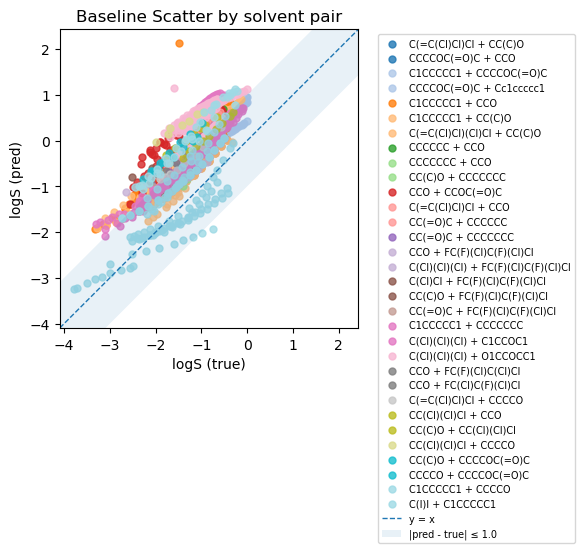

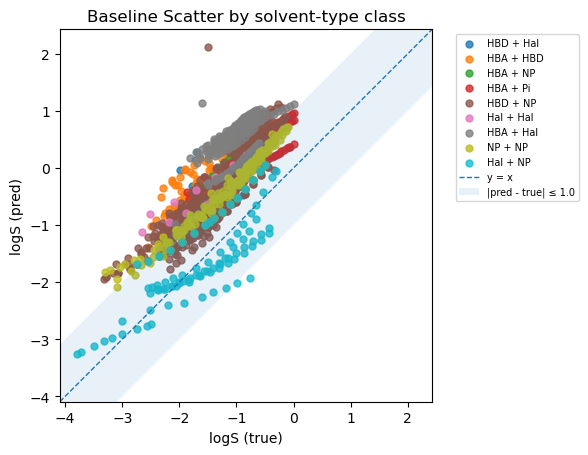

In [17]:
baseline_model, baseline_pred_csv, baseline_pair_csv = run_baseline_linear()


In [ ]:
from dataclasses import dataclass
from typing import List, Optional, Tuple

@dataclass
class Config:
    # ====== 数据 & 路径相关 ======
    mixture_csv: str           # 混合溶剂原始 CSV（比如 mix_noaq.csv）
    out_dir: str               # 所有结果输出目录
    exp_name: str              # 实验名字前缀
    encoder_ckpts: List[str]   # 4 个 encoder 的路径列表
    space_indices: Optional[List[int]]  # 使用哪些 encoder，如果 None 就用全部
    model_ckpt: str            # ✅ pairwise 回归模型 checkpoint（如 ckpt/leeds.pth）

    # ====== 结构超参数（要和你原来训练 pair 模型时一致）======
    emb_dim: int = 512
    mlp_hidden: Tuple[int, ...] = (1024, 128, 64)
    mlp_dropout: float = 0.2
    t_embed_dim: int = 16
    solute_dropout: float = 0.3
    solvent_dropout: float = 0.3

    # ====== Transformer 头的训练超参数 ======
    num_epochs: int = 50
    lr: float = 1e-3
    weight_decay: float = 1e-4

    # ====== Transformer 结构超参数 ======
    # 注意：这里我默认 d_model = emb_dim = 512，避免跟原 MLP 维度不匹配
    attn_d_model: int = 512
    attn_heads: int = 4
    attn_layers: int = 2
    attn_ff_dim: int = 1024
    attn_dropout: float = 0.1
    attn_hidden: int = 128


# ====== 实例化一个全局 cfg（baseline + transformer 都共用）======

cfg = Config(
    mixture_csv="mix_noaq.csv",
    out_dir="results/mixture_tests_noaq",
    exp_name="jupyter_test",

    encoder_ckpts=[
        "ckpt/tau_0.1__scale_0.25/task_0/best_model.pth",
        "ckpt/tau_0.1__scale_0.25/task_1/best_model.pth",
        "ckpt/tau_0.1__scale_0.25/task_2/best_model.pth",
        "ckpt/tau_0.1__scale_0.25/task_none/best_model.pth",
    ],
    space_indices=None,              # 使用全部4个空间
    model_ckpt="ckpt/leeds.pth",     # ✅ pairwise 微调好的模型

    # 下面这些可以按需要改：
    num_epochs=50,
    lr=1e-3,
    weight_decay=1e-4,

    # 如果你想让 Transformer 的 d_model 跟原 embedding 一致，就保持 512
    attn_d_model=512,
    attn_heads=4,
    attn_layers=2,
    attn_ff_dim=1024,
    attn_dropout=0.1,
    attn_hidden=128,
)

# 和你原来逻辑保持一致：同步全局 EMB_DIM
EMB_DIM = cfg.emb_dim
print("Config loaded. EMB_DIM =", EMB_DIM)
print("Pairwise model ckpt =", cfg.model_ckpt)


Config loaded. EMB_DIM = 512
Pairwise model ckpt = ckpt/leeds.pth


c:\Users\chenxinyi\Documents\GitHub\ChemSpaceAlign\finetune_pair.py:383: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ck = torch.load(path, map_location=device)
C:\Users\ch

[rename-load] Missing keys after remap: []
[rename-load] Unexpected keys after remap: []
[attn-init] detected z_dim_new (solute representation dim) = 512
[attn-init] trainable params = 5940515
[data] Loaded mixture dataset: 1440 samples
[data] Split done: train=1152, val=144, test=144
[attn-init] detected z_dim_new (solute representation dim) = 512
[attn-init] trainable params = 5940515
Attn Mixture Test 'mix_noaq': MSE=2.1915, pct(|pred - logS| <= 1)=0.306
[pair-summary] Saved 22 rows to: results/mixture_tests_noaq\attn\jupyter_test_0_1_2_3_mix_noaq_attn_pairs.csv
Top solvent combinations by average MSE:
                             solventA_name          solventB_name  \
0                         Trichloromethane        Tetrahydrofuran   
1                                  Heptane            Propan-2-ol   
2                                  Ethanol         Butylethanoate   
3                           Butylethanoate          Methylbenzene   
4                              Propan-2-ol

C:\Users\chenxinyi\AppData\Local\Temp\ipykernel_37464\1014236958.py:141: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap_pairs = plt.cm.get_cmap("tab20", n_pairs)
C:\Users\chenxinyi\AppData\Local\Temp\ipykernel_37464\1014236958.py:153: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap_cls = plt.cm.get_cmap("tab10", n_classes)


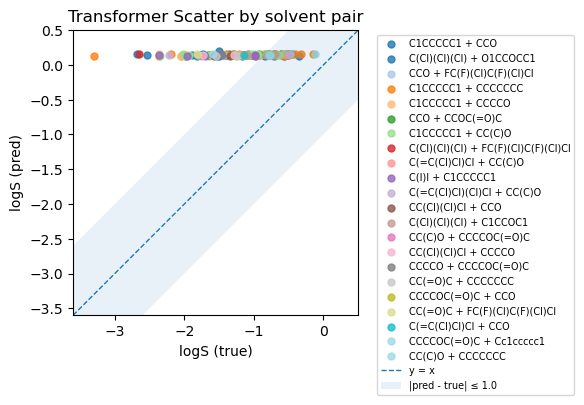

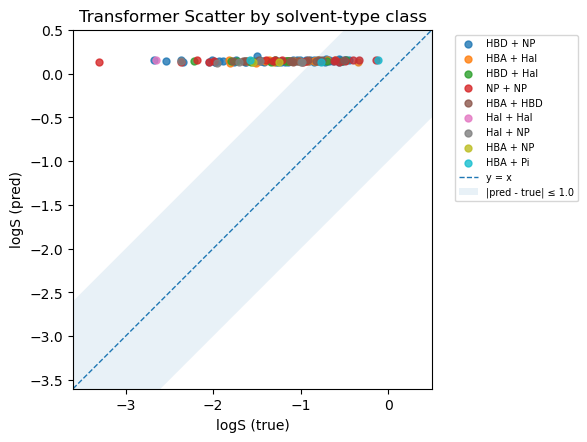

In [36]:
attn_model, attn_pred_csv, attn_pair_csv = run_transformer_attn()